In [1]:
import numpy as np
import matplotlib.pyplot as plt
from opt_einsum import contract
import jax
import jax.numpy as jnp

import sys
import os
sys.path.append('..')

from mctdhf.MCTDHF_direct_jax import MCTDHF
from mctdhf.MCTDHF_n_species import MCTDHF_n_species
from mctdhf.integrators import *
from mctdhf.electron_integrals import *

In [2]:
# Number of spatial orbitals
num_spatial_orbitals = 20
# Number of electrons
num_alpha_electrons = 1
num_beta_electrons = 1
# Number of MCTDHF orbitals
num_mctdhf_orbitals = 1

In [3]:
# Finite-Difference (same parameters as in Zhangellini)
x = np.linspace(-10, 10, 201)
pot = HOPotential(0.25)

spf, h = get_spf_and_diag_h(num_spatial_orbitals, x, pot)
g = coulomb_interaction_matrix_elements(spf, spf, x, x, kappa = 1, a = 0.25)

ht = (x[1]-x[0])*contract('ij, j, kj -> ik', spf.conj(), x, spf)

@jax.jit
def h_t(t, ht=ht):
    return ht*jnp.sin(2*t)

In [4]:
mctdhf = MCTDHF(jnp.array(h), lambda t: 0, jnp.array(g), num_mctdhf_orbitals, 
                    num_spatial_orbitals, num_alpha_electrons, 
                    num_beta_electrons, imag_time=True)

# Test with this instead of Crank-Nicolson:
#integrator = get_runge_kutta_4_solver(mctdhf, dt=0.1)
#integrator = get_crank_nicolson_fixed_iter(mctdhf, dt=0.1, num_iter=5)
integrator = get_crank_nicolson_solver(mctdhf, dt=0.1, max_iter=5)

ts, Es, Cs, bs_alpha, bs_beta = mctdhf.integrate(integrator, num_steps=1000)

W0123 17:22:43.263849 1862134 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W0123 17:22:43.266726 1861928 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


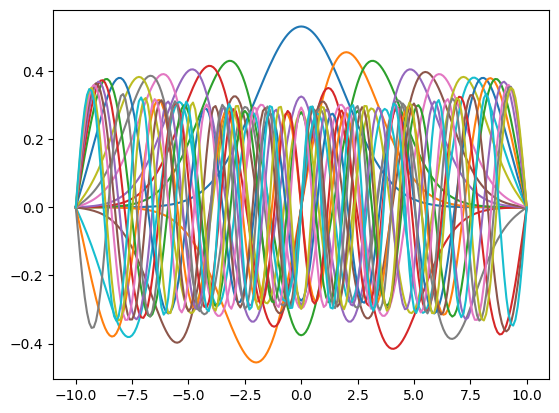

In [5]:
plt.plot(x, spf.T)

/home/oskar/projects/n-species-mctdh/test/venv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/oskar/projects/n-species-mctdh/test/venv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


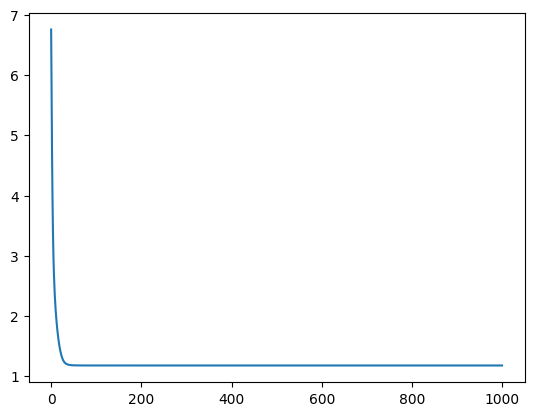

In [6]:
plt.plot(Es)

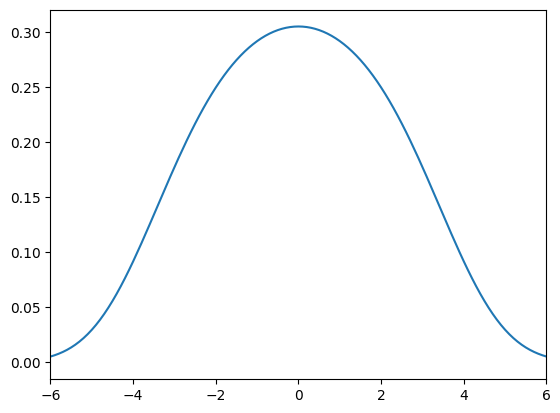

In [7]:
particle_densities = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
plt.plot(x, np.real(particle_densities)[0])
#plt.plot(x, pot(x)/np.max(pot(x)), label='Scaled potential')
plt.xlim(-6,6)
plt.show()

In [8]:
bs_alpha[-1].shape

(20, 1)

In [9]:
ra, rb = mctdhf.get_full_basis_1p_RDM(Cs[-1], bs_alpha[-1][None,:,:], bs_beta[-1][None,:,:])

(0.0, 0.4)

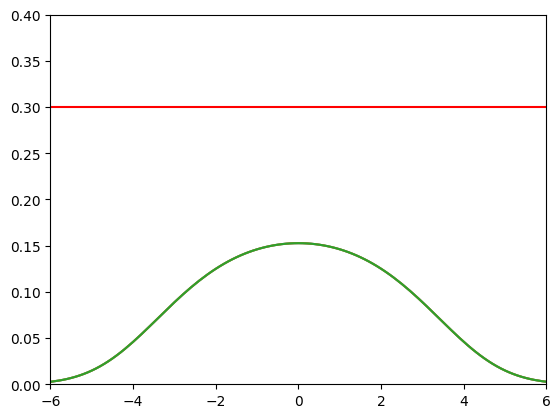

In [10]:
pa = contract("ix,aij,jx->x", spf, ra, spf)
pb = contract("ix,bij,jx->x", spf, rb, spf)
plt.plot(x, 0.5*(np.abs(pa)+np.abs(pb)))
plt.plot(x, pa)
plt.plot(x, pb)
plt.hlines(0.3, -6, 6, colors="r")
plt.xlim(-6,6)
plt.ylim(0,0.4)

In [11]:
from scipy.special import comb

In [12]:
dt = 1e-2
num_steps = int(4*2*np.pi/(0.25*8*dt))

#Ms = [1]
#Ms = [2,4,6]
Ms = [1,2,3,4]

In [13]:
particle_densities = np.zeros((len(Ms), len(x)))
overlaps = np.zeros((len(Ms), num_steps+1))
gs_energies = np.zeros_like(Ms, np.double)
Es_imag_time = np.zeros((len(Ms), 1001))

for i,M in enumerate(Ms):
    rng = np.random.default_rng(42) # Use same seed for all species to ensure symmetry if dimensions match
    r = rng.random((num_spatial_orbitals, M))
    u, _, vh = np.linalg.svd(r, full_matrices=False)
    b_init = jnp.array((u @ vh), jnp.complex64)

    # num_mctdhf_orbitals = M
    # M = comb(M, 2, exact=True)
    # spf, h = get_spf_and_diag_h(num_spatial_orbitals, x, pot)
    # g = coulomb_interaction_matrix_elements(spf, spf, x, x, kappa = 1, a = 0.25)

    # ht = (x[1]-x[0])*contract('ij, j, kj -> ik', spf.conj(), x, spf)

    # @jax.jit
    # def h_t(t, ht=ht):
    #     return ht*jnp.sin(2*t)

    mctdhf = MCTDHF(jnp.array(h), lambda t: 0, jnp.array(g), M, 
                    num_spatial_orbitals, num_alpha_electrons, 
                    num_beta_electrons, imag_time=True)
    
    #integrator = get_crank_nicolson_solver(mctdhf, dt)
    #integrator = get_runge_kutta_4_solver(mctdhf, dt)
    #integrator = get_crank_nicolson_fixed_iter(mctdhf, dt)
    integrator = get_crank_nicolson_solver(mctdhf, dt=1e-1, max_iter=5)

    ts, Es, Cs, bs_alpha, bs_beta = mctdhf.integrate(integrator, num_steps = 1000, b_alpha_init=b_init, b_beta_init=b_init)
    particle_densities[i,:] = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
    gs_energies[i] = np.real(np.array(Es[-1]))
    Es_imag_time[i, :] = np.array(Es)[:,0]

    mctdhf_rt = MCTDHF(h, h_t, g, M, 
                num_spatial_orbitals, num_alpha_electrons, 
                num_beta_electrons, imag_time=False)


    #integrator_rt = get_runge_kutta_4_solver(mctdhf_rt, dt)
    #integrator_rt = get_crank_nicolson_fixed_iter(mctdhf_rt, dt)
    integrator_rt = get_crank_nicolson_solver(mctdhf_rt, dt, max_iter=5)
    
    ts_rt, Es_rt, Cs_rt, bs_rt_alpha, bs_rt_beta = mctdhf_rt.integrate(integrator_rt, num_steps = num_steps, t_init = 0, 
                                                b_alpha_init = jnp.array(bs_alpha[-1]), b_beta_init = jnp.array(bs_beta[-1]), C_init = jnp.array(Cs[-1]))

    overlaps[i,:] = (np.abs(np.array([mctdhf.calculate_overlap(bs_alpha[-1], bs_beta[-1], Cs[-1], b_alpha, b_beta, C) for b_alpha, b_beta, C in zip(bs_rt_alpha, bs_rt_beta, Cs_rt)]))**2)[:,0]

/tmp/ipykernel_1861928/3955479610.py:33: ComplexWarning: Casting complex values to real discards the imaginary part
  particle_densities[i,:] = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
/tmp/ipykernel_1861928/3955479610.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gs_energies[i] = np.real(np.array(Es[-1]))
/tmp/ipykernel_1861928/3955479610.py:35: ComplexWarning: Casting complex values to real discards the imaginary part
  Es_imag_time[i, :] = np.array(Es)[:,0]


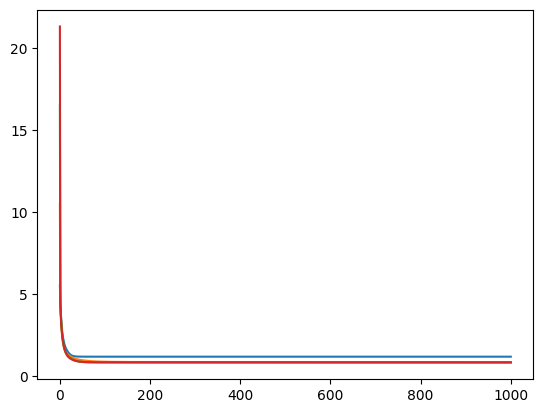

In [14]:
plt.plot(Es_imag_time.T)


Ground state energies
M=1: 1.1795690059661865
M=2: 0.8532140254974365
M=3: 0.8263106942176819
M=4: 0.8300673961639404


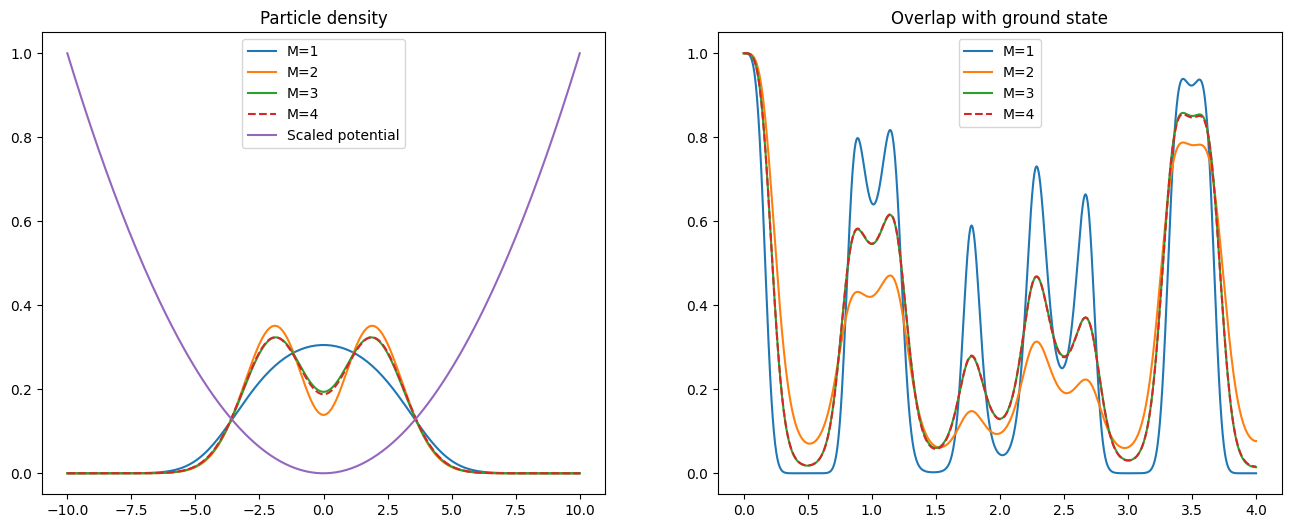

In [15]:
t = np.linspace(0, 4, num_steps+1)
styles = ['-', '-', '-', '--']


fig, axs = plt.subplots(1, 2, figsize=(16,6))

print("Ground state energies")
for i,M in enumerate(Ms):
    print(f'M={M}: {gs_energies[i]}')
    axs[0].plot(x, particle_densities[i], label=f'M={M}', ls=styles[i])
    axs[1].plot(t, overlaps[i], label=f'M={M}', ls=styles[i])


axs[0].plot(x, pot(x)/np.max(pot(x)), label='Scaled potential')

axs[0].set_title('Particle density')
axs[1].set_title('Overlap with ground state')

for a in axs:
    a.legend()
plt.show()


In [16]:
@jax.jit
def h_t_n(t, h=jnp.array(h), ht=jnp.array(ht)):
    return h + ht*jnp.sin(2*t)

In [23]:
num_imag_time_steps = 1000
Ms = [1, 2, 3, 4]

particle_densities_n = np.zeros((len(Ms), len(x)))
overlaps_n = np.zeros((len(Ms), num_steps+1))
gs_energies_n = np.zeros_like(Ms, np.double)
Es_imag_time_n = np.zeros((len(Ms), num_imag_time_steps+1))

h_list_imag = [jnp.array(h), jnp.array(h)]
h_list_real = [h_t_n, h_t_n]
g_dict = {
        (0,0): g, # alpha-alpha
        (1,1): g, # beta-beta
        (0,1): g  # alpha-beta
    }

for i,M in enumerate(Ms):
    rng = np.random.default_rng(42) # Use same seed for all species to ensure symmetry if dimensions match
    r = rng.random((num_spatial_orbitals, M))
    u, _, vh = np.linalg.svd(r, full_matrices=False)
    b_init = jnp.array((u @ vh), jnp.complex64)
    bs_init_list = [b_init, b_init]

    mctdhf_n = MCTDHF_n_species(h_list = h_list_imag, 
                                g_dict = g_dict, 
                                num_particles = [num_alpha_electrons, num_beta_electrons], 
                                num_mctdhf_orbitals = [M, M], 
                                num_spatial_orbitals = [num_spatial_orbitals, num_spatial_orbitals],
                                imag_time = True)
    

    integrator = get_crank_nicolson_solver(mctdhf_n, dt=1e-1, max_iter=5)

    ts, ys = mctdhf_n.integrate(integrator, num_steps = num_imag_time_steps, bs_init_list = bs_init_list)
    Cs, bs = mctdhf_n._y_to_Cb(ys[-1])
    particle_densities_n[i,:] = np.sum(np.abs(mctdhf_n.calculate_particle_densities(Cs, bs, [spf, spf])), axis=0)
    gs_energies_n[i] = np.real(mctdhf_n.calculate_energy(ts[-1], ys[-1])[0])
    Es_imag_time_n[i,:] = np.array([np.real(mctdhf_n.calculate_energy(ts[j], ys[j])[0]) for j in range(num_imag_time_steps+1)])

    mctdhf_rt_n = MCTDHF_n_species(h_list = h_list_real, 
                                g_dict = g_dict, 
                                num_particles = [num_alpha_electrons, num_beta_electrons], 
                                num_mctdhf_orbitals = [M, M], 
                                num_spatial_orbitals = [num_spatial_orbitals, num_spatial_orbitals],
                                imag_time = False)


    integrator_rt_n = get_crank_nicolson_solver(mctdhf_rt_n, dt, max_iter=10)
    #integrator_rt_n = get_rk4_solver(mctdhf_rt_n, dt)
    
    ts_rt, ys_rt = mctdhf_rt_n.integrate(integrator_rt_n, 
                                        num_steps = num_steps, 
                                        t_init = 0, 
                                        bs_init_list = bs,
                                        C_init = jnp.array(Cs))

    for j in range(num_steps+1):
        overlaps_n[i,j] = np.abs(mctdhf_rt_n.calculate_overlap(ys[-1], ys_rt[j])[0])**2

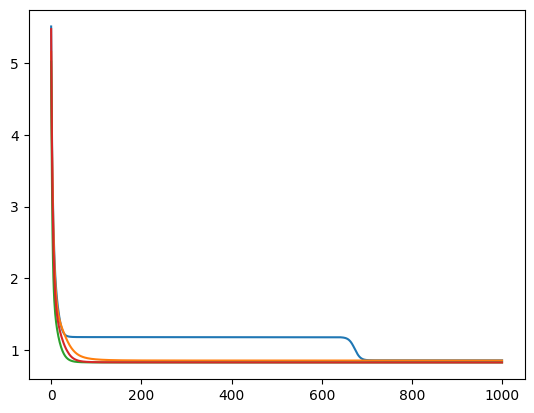

In [24]:
plt.plot(Es_imag_time_n.T)

Ground state energies
M=1: 0.8556791543960571
M=2: 0.8528153896331787
M=3: 0.8261395692825317
M=4: 0.8258143663406372


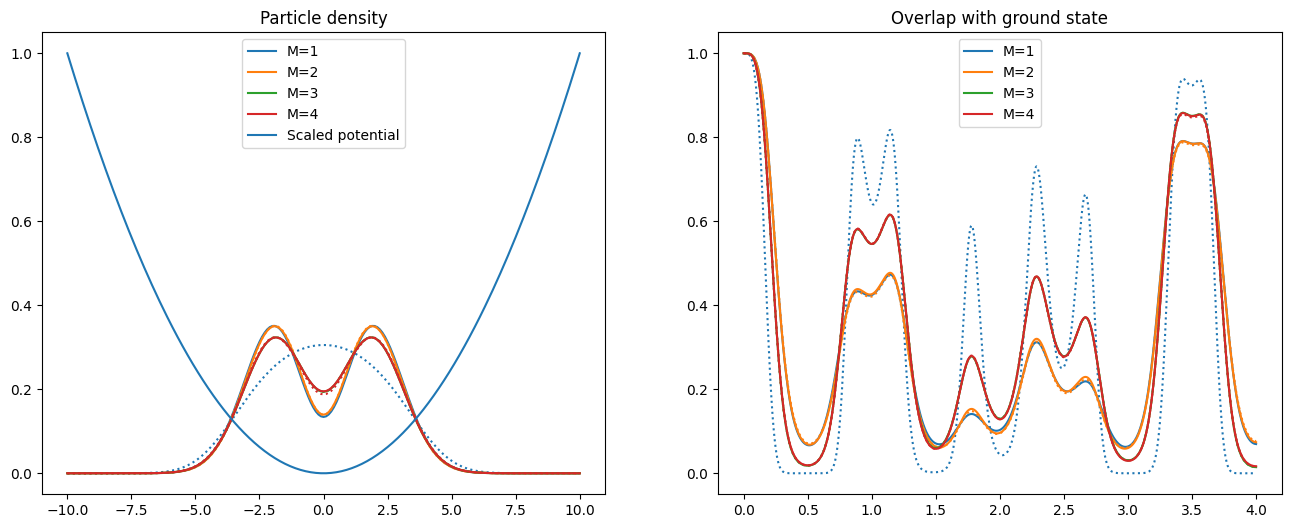

In [25]:
t = np.linspace(0, 4, num_steps+1)


fig, axs = plt.subplots(1, 2, figsize=(16,6))

print("Ground state energies")
for i,M in enumerate(Ms):
    print(f'M={M}: {gs_energies_n[i]}')
    axs[0].plot(x, particle_densities_n[i], f'C{i}-', label=f'M={M}')
    axs[1].plot(t, overlaps_n[i], f'C{i}-', label=f'M={M}')

    axs[0].plot(x, particle_densities[i], f'C{i}:')
    axs[1].plot(t, overlaps[i], f'C{i}:')

# for i in [2,3]:
#     axs[0].plot(x, particle_densities[i], f'C{i}--', label=f'M={i+1}')
#     axs[1].plot(t, overlaps[i], f'C{i}--', label=f'M={i+1}')

axs[0].plot(x, pot(x)/np.max(pot(x)), label='Scaled potential')

axs[0].set_title('Particle density')
axs[1].set_title('Overlap with ground state')

for a in axs:
    a.legend()
plt.show()
